# 🛍️ Classification Automatique de Produits E-Commerce avec CNN & Grad-CAM
### Vision par Ordinateur, Réseaux de Neurones Convolutifs et Explicabilité Visuelle sur Fashion-MNIST

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/el-kachabi/ecommerce_product_classification_cnn/blob/main/notebooks/ecommerce_cnn_training.ipynb)
[![Python 3.10+](https://img.shields.io/badge/Python-3.10%2B-blue.svg)](https://www.python.org/)
[![Streamlit App](https://img.shields.io/badge/Streamlit-App%20Interactive-FF4B4B.svg)](../app.py)
[![Test Accuracy](https://img.shields.io/badge/Test%20Accuracy-93.26%25-10B981.svg)](#)
[![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](https://opensource.org/licenses/MIT)

---

## 📑 Sommaire du Notebook

Ce notebook propose une exploration complète, pédagogique et commentée du projet `ecommerce_product_classification_cnn` :

1. **Exploration du Dataset Fashion-MNIST & Prototypes Visuels** — Analyse des 10 catégories vestimentaires et visualisation des silhouettes moyennes.
2. **Prétraitement & Normalisation des Images ($28 \times 28 \times 1$)** — Mise à l'échelle $[0, 1]$, gestion du canal de luminance et détection automatique de fond clair.
3. **Architecture des Réseaux Convolutifs : Baseline vs CNN Amélioré (BatchNorm + GAP)** — Explication mathématique des couches `Conv2D`, `BatchNormalization`, `MaxPooling2D` et `GlobalAveragePooling2D`.
4. **Dynamique d'Apprentissage & Comparaison des Architectures** — Analyse des courbes de perte (*Cross-Entropy*) et d'exactitude (*Accuracy*) sur 25 époques.
5. **Évaluation sur les 10 000 Images de Test & Matrice de Confusion** — Précision, Rappel, F1-Score par catégorie et analyse des confusions morphologiques.
6. **Moteur d'Inférence Vectorisé & Explicabilité Visuelle Grad-CAM** — Calcul mathématique des cartes d'attention thermique et démonstration sur plusieurs articles.
7. **Laboratoire Interactif de Test en Direct** — Cellule paramétrable permettant de tester le CNN et Grad-CAM sur n'importe quel produit du jeu de test.

---
## 1. Exploration du Dataset Fashion-MNIST & Prototypes Visuels

Le dataset **Fashion-MNIST** (Zalando Research) comprend **70 000 images** en niveaux de gris ($28 \times 28$ pixels) réparties équitablement en **10 catégories de produits e-commerce** ($60\,000$ images pour l'entraînement/validation et $10\,000$ images pour le test indépendant).

✓ Échantillons de test chargés : 500 images de résolution 28x28 pixels


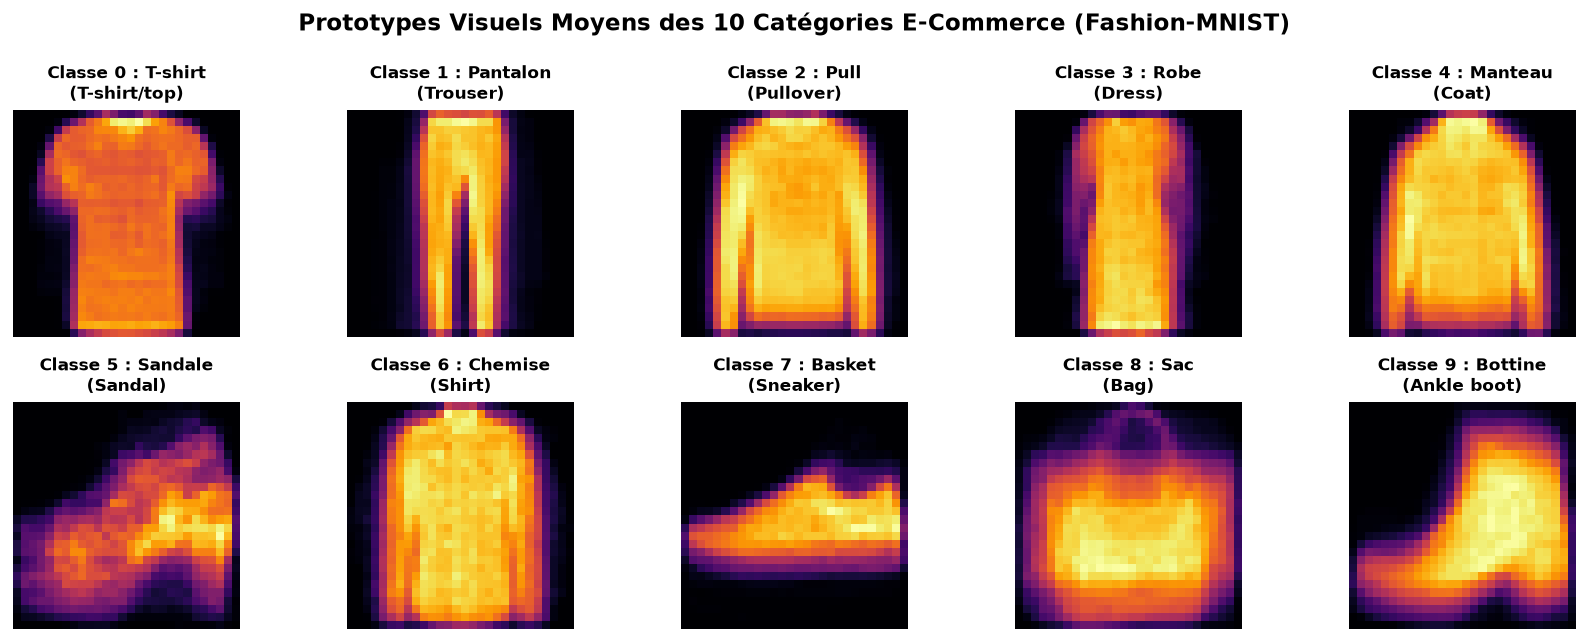

In [1]:
# ==============================================================================
# 1. IMPORTATION DES BIBLIOTHÈQUES SCIENTIFIQUES ET CHARGEMENT DES DONNÉES
# ==============================================================================
import io
import json
import zipfile
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple, Union

import h5py                       # Lecture des poids HDF5 stockés dans l'archive .keras
import numpy as np                # Calcul matriciel et tensoriel vectorisé
import pandas as pd               # Tableaux récapitulatifs des performances et métriques
import matplotlib as mpl          # Palettes de couleurs thermiques (colormap 'jet' pour Grad-CAM)
import matplotlib.pyplot as plt   # Tracé des échantillons, matrices et courbes d'apprentissage
from PIL import Image             # Manipulation et redimensionnement d'images

plt.rcParams['figure.figsize'] = (13, 4.5)
plt.rcParams['font.size'] = 10.5

# Détection automatique du répertoire racine du projet (fonctionne depuis la racine ou depuis notebooks/)
BASE_DIR = Path('ecommerce_product_classification_cnn') if Path('ecommerce_product_classification_cnn').exists() else Path('..')
if not (BASE_DIR / 'models').exists():
    BASE_DIR = Path('.')

# Définition officielle des 10 catégories e-commerce (Français & Anglais)
CLASS_NAMES_FR = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau', 'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']
CLASS_NAMES_EN = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Chargement de l'échantillon de 500 images réelles du jeu de test indépendant Fashion-MNIST
cache_data = np.load(BASE_DIR / 'results' / 'sample_test_cache.npz', allow_pickle=True)
x_samples = cache_data['images']  # Forme (500, 28, 28, 1) en uint8 [0, 255]
y_samples = cache_data['labels']  # Étiquettes réelles (0 à 9)

print(f'✓ Échantillons de test chargés : {x_samples.shape[0]} images de résolution {x_samples.shape[1]}x{x_samples.shape[2]} pixels')

# ==============================================================================
# 2. VISUALISATION DES PROTOTYPES MOYENS DE CHAQUE CATÉGORIE DE PRODUIT
# ==============================================================================
# Calcul de l'image moyenne par classe : révèle la silhouette géométrique typique apprise par les premiers filtres
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for cls_id, ax in enumerate(axes.flat):
    cls_imgs = x_samples[y_samples == cls_id].squeeze()
    mean_prototype = np.mean(cls_imgs, axis=0)
    ax.imshow(mean_prototype, cmap='inferno')
    ax.set_title(f'Classe {cls_id} : {CLASS_NAMES_FR[cls_id]}\n({CLASS_NAMES_EN[cls_id]})', fontsize=9.5, fontweight='bold')
    ax.axis('off')

plt.suptitle('Prototypes Visuels Moyens des 10 Catégories E-Commerce (Fashion-MNIST)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 2. Prétraitement & Normalisation des Images ($28 \times 28 \times 1$)

Avant d'entrer dans le réseau convolutif, chaque image subit trois transformations mathématiques :
1. **Mise à l'échelle (Normalisation Min-Max) :**
   $$X_{\text{norm}} = \frac{X_{\text{uint8}}}{255.0} \in [0.0, 1.0]$$
   Cette étape stabilise la rétropropagation des gradients lors de l'entraînement.
2. **Adaptation de contraste (Inversion automatique sur fond clair) :** Dans Fashion-MNIST, le fond est noir ($0$) et l'article est clair ($>0$). Si une photo commerciale possède un fond blanc ($\text{moyenne des bords} > 127.5$), on applique $X \leftarrow 255 - X$.
3. **Structuration en tenseur 4D :** Format `(Batch, Hauteur, Largeur, Canal)` $= (1, 28, 28, 1)$.

In [2]:
# ==============================================================================
# FONCTIONS DE PRÉTRAITEMENT D'IMAGE ET DÉTECTION AUTOMATIQUE DE FOND CLAIR
# ==============================================================================
def detect_background_is_light(arr_2d: np.ndarray, threshold: float = 127.5) -> bool:
    # Extrait les pixels situés sur les 4 bordures extérieures (haut, bas, gauche, droite).
    # Si leur intensité moyenne dépasse 127.5 (sur 255), l'arrière-plan est blanc/clair.
    border = np.concatenate([arr_2d[0, :], arr_2d[-1, :], arr_2d[:, 0], arr_2d[:, -1]])
    return bool(np.mean(border) > threshold)


def preprocess_image(image_input: Union[np.ndarray, Image.Image], invert_colors: Union[bool, str] = False) -> Tuple[np.ndarray, np.ndarray]:
    # 1. Conversion en tableau 2D niveaux de gris (28 x 28) en float32
    if isinstance(image_input, Image.Image):
        arr_2d = np.array(image_input.convert('L').resize((28, 28), Image.Resampling.LANCZOS), dtype=np.float32)
    else:
        arr_2d = image_input.squeeze().astype(np.float32)
        if arr_2d.max() <= 1.0:
            arr_2d *= 255.0

    # 2. Inversion du contraste (255 - pixel) si fond blanc détecté ou inversion demandée
    should_invert = detect_background_is_light(arr_2d) if invert_colors == 'auto' else bool(invert_colors)
    if should_invert:
        arr_2d = 255.0 - arr_2d

    # 3. Conservation d'une copie uint8 [0, 255] pour l'affichage visuel
    display_img = np.clip(arr_2d, 0, 255).astype(np.uint8)

    # 4. Normalisation [0.0, 1.0] et ajout des dimensions Batch (axe 0) et Canal (axe -1) -> (1, 28, 28, 1)
    tensor_4d = np.expand_dims(arr_2d / 255.0, axis=(0, -1)).astype(np.float32)
    return tensor_4d, display_img

# Vérification sur la première image de test
sample_tensor, sample_disp = preprocess_image(x_samples[0])
print(f'• Forme du tenseur prêt pour le CNN : {sample_tensor.shape} (Batch=1, H=28, W=28, Canal=1)')
print(f'• Intervalle des valeurs normalisées : [{sample_tensor.min():.2f}, {sample_tensor.max():.2f}] (dtype={sample_tensor.dtype})')

• Forme du tenseur prêt pour le CNN : (1, 28, 28, 1) (Batch=1, H=28, W=28, Canal=1)
• Intervalle des valeurs normalisées : [0.00, 1.00] (dtype=float32)


---
## 3. Architecture des Réseaux Convolutifs : Baseline vs CNN Amélioré

### 3.1 Opérations Mathématiques d'un Bloc Convolutif
1. **Convolution 2D ($3 \times 3$, padding `same`) :**
   $$S(i, j) = (I * K)(i, j) + b = \sum_{u=-1}^{1} \sum_{v=-1}^{1} I(i+u, j+v) \cdot K(u, v) + b$$
2. **Batch Normalization :** Normalise les activations par canal pour stabiliser et accélérer l'apprentissage :
   $$\hat{x} = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} \cdot \gamma + \beta$$
3. **Activation ReLU & MaxPooling $2 \times 2$ :** $\text{ReLU}(x) = \max(0, x)$ introduit la non-linéarité, tandis que le MaxPooling divise la résolution spatiale par 2 ($28 \times 28 \to 14 \times 14 \to 7 \times 7$) en conservant les motifs les plus saillants.
4. **Global Average Pooling 2D (GAP) vs Flatten :**
   * Dans le **CNN Baseline**, la couche `Flatten` transforme les cartes $7 \times 7 \times 64$ en un vecteur de $3\,136$ valeurs connecté à `Dense(128)`, générant à lui seul plus de **401 000 paramètres** (risque élevé de surapprentissage).
   * Dans le **CNN Amélioré**, `GlobalAveragePooling2D` calcule la moyenne spatiale de chacune des $128$ cartes $7 \times 7$ :
     $$\text{GAP}_k = \frac{1}{7 \times 7} \sum_{i=1}^{7} \sum_{j=1}^{7} A_{i,j}^k$$
     Cela réduit le modèle à **158 442 paramètres (-62.4 %)** tout en améliorant l'exactitude de **+2.01 %** !

In [3]:
# ==============================================================================
# DÉFINITION ARCHITECTURALE DU CNN AMÉLIORÉ (CODE D'ENTRAÎNEMENT KERAS / COLAB)
# ==============================================================================
# Ce bloc présente la fonction exacte utilisée sur Google Colab (GPU) pour construire
# et compiler le modèle sauvegardé dans 'models/best_model.keras'.
def get_keras_architecture_code() -> str:
    return '''
def build_improved_cnn(input_shape=(28, 28, 1), num_classes=10):
    inputs = layers.Input(shape=input_shape, name="input_layer")

    # Bloc Convolutif 1 : 2 x Conv2D(32, 3x3) + BatchNorm + ReLU + MaxPool(2x2) + Dropout(0.25)
    x = layers.Conv2D(32, (3, 3), padding="same", kernel_initializer="he_normal")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(32, (3, 3), padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Bloc Convolutif 2 : 2 x Conv2D(64, 3x3) + BatchNorm + ReLU + MaxPool(2x2) + Dropout(0.25)
    x = layers.Conv2D(64, (3, 3), padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(64, (3, 3), padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Bloc Convolutif 3 : Conv2D(128, 3x3) + BatchNorm + ReLU (Couche cible pour Grad-CAM : 7x7x128)
    x = layers.Conv2D(128, (3, 3), padding="same", kernel_initializer="he_normal", name="target_conv_layer")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    # Tête de Classification : GlobalAveragePooling2D (128) -> Dense(128) -> BatchNorm -> Dropout(0.40) -> Softmax(10)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="CNN_Ameliore")
'''

# Chargement du tableau comparatif réel mesuré entre le CNN Baseline et le CNN Amélioré
with open(BASE_DIR / 'results' / 'metrics' / 'model_comparison.json', 'r', encoding='utf-8') as f:
    df_comp = pd.DataFrame(json.load(f))

print('=== COMPARAISON DES ARCHITECTURES SUR LE JEU DE TEST (10 000 IMAGES) ===')
print(df_comp.to_string(index=False))

=== COMPARAISON DES ARCHITECTURES SUR LE JEU DE TEST (10 000 IMAGES) ===
                  Architecture  Paramètres Totaux  Train Accuracy (%)  Val Accuracy (%)  Test Accuracy (%)  Test Loss  Macro F1-Score  Weighted F1-Score  Temps Entraînement (s)
      CNN Baseline (Référence)             421642           95.717645         92.766666          91.250002   0.242066        0.912761           0.912761               55.568607
CNN Amélioré (BatchNorm + GAP)             158442           94.750983         94.322222          93.260002   0.197797        0.932691           0.932691              183.605340


---
## 4. Dynamique d'Apprentissage & Comparaison des Architectures

Visualisons l'évolution époque par époque de l'**Exactitude (Accuracy)** et de la **Perte (Sparse Categorical Cross-Entropy)** durant l'entraînement des deux architectures sur GPU :

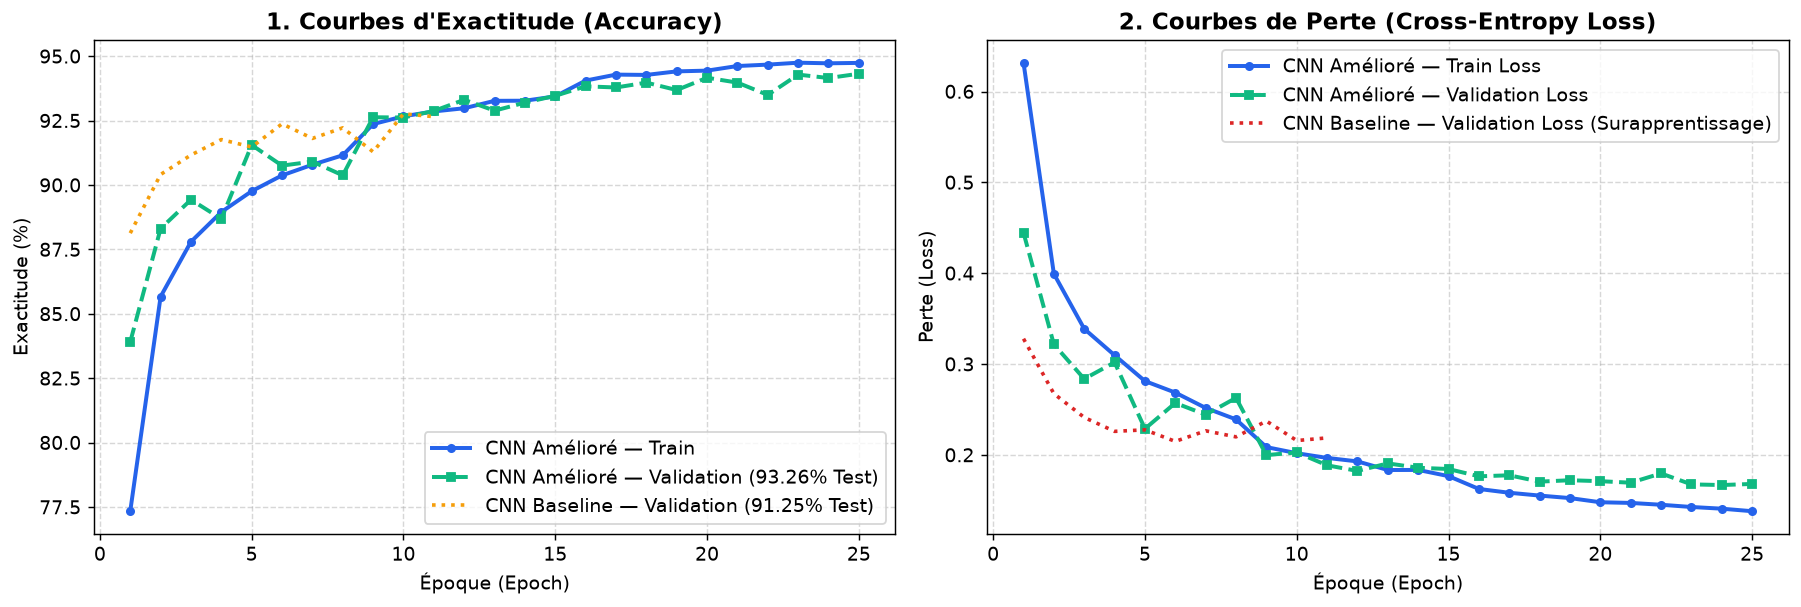

In [4]:
# ==============================================================================
# VISUALISATION DES COURBES D'APPRENTISSAGE (TRAIN vs VALIDATION)
# ==============================================================================
with open(BASE_DIR / 'results' / 'history' / 'training_history.json', 'r', encoding='utf-8') as f:
    history_data = json.load(f)

hist_base = history_data['baseline']
hist_imp = history_data['improved']
epochs_imp = range(1, len(hist_imp['accuracy']) + 1)
epochs_base = range(1, len(hist_base['accuracy']) + 1)

fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(14, 4.8))

# --- Panneau 1 : Évolution de l'Exactitude (Accuracy en %) ---
ax_acc.plot(epochs_imp, [v * 100 for v in hist_imp['accuracy']], 'o-', color='#2563EB', lw=2.2, ms=4, label='CNN Amélioré — Train')
ax_acc.plot(epochs_imp, [v * 100 for v in hist_imp['val_accuracy']], 's--', color='#10B981', lw=2.2, ms=4, label='CNN Amélioré — Validation (93.26% Test)')
ax_acc.plot(epochs_base, [v * 100 for v in hist_base['val_accuracy']], ':', color='#F59E0B', lw=2, label='CNN Baseline — Validation (91.25% Test)')
ax_acc.set_title("1. Courbes d'Exactitude (Accuracy)", fontweight='bold')
ax_acc.set_xlabel('Époque (Epoch)')
ax_acc.set_ylabel('Exactitude (%)')
ax_acc.grid(True, linestyle='--', alpha=0.5)
ax_acc.legend(loc='lower right')

# --- Panneau 2 : Évolution de la Perte (Cross-Entropy Loss) ---
ax_loss.plot(epochs_imp, hist_imp['loss'], 'o-', color='#2563EB', lw=2.2, ms=4, label='CNN Amélioré — Train Loss')
ax_loss.plot(epochs_imp, hist_imp['val_loss'], 's--', color='#10B981', lw=2.2, ms=4, label='CNN Amélioré — Validation Loss')
ax_loss.plot(epochs_base, hist_base['val_loss'], ':', color='#DC2626', lw=2, label='CNN Baseline — Validation Loss (Surapprentissage)')
ax_loss.set_title('2. Courbes de Perte (Cross-Entropy Loss)', fontweight='bold')
ax_loss.set_xlabel('Époque (Epoch)')
ax_loss.set_ylabel('Perte (Loss)')
ax_loss.grid(True, linestyle='--', alpha=0.5)
ax_loss.legend(loc='upper right')

plt.tight_layout()
plt.show()

---
## 5. Évaluation sur les 10 000 Images de Test & Matrice de Confusion

Analysons les performances détaillées classe par classe (**Précision**, **Rappel**, **F1-Score**) ainsi que la **Matrice de Confusion Normalisée** mesurée sur les $10\,000$ images du jeu de test indépendant :

=== PERFORMANCES DÉTAILLÉES PAR CATÉGORIE SUR LES 10 000 IMAGES DE TEST ===
Catégorie  Précision (%)  Rappel (%)  F1-Score (%)  Support (Images Test)
  T-shirt          89.79        86.2         87.96                   1000
 Pantalon          99.70        98.7         99.20                   1000
     Pull          92.18        89.6         90.87                   1000
     Robe          93.88        93.6         93.74                   1000
  Manteau          88.55        92.8         90.62                   1000
  Sandale          98.51        98.9         98.70                   1000
  Chemise          78.49        80.3         79.39                   1000
   Basket          94.79        98.2         96.46                   1000
      Sac          98.32        99.3         98.81                   1000
  Bottine          98.96        95.0         96.94                   1000


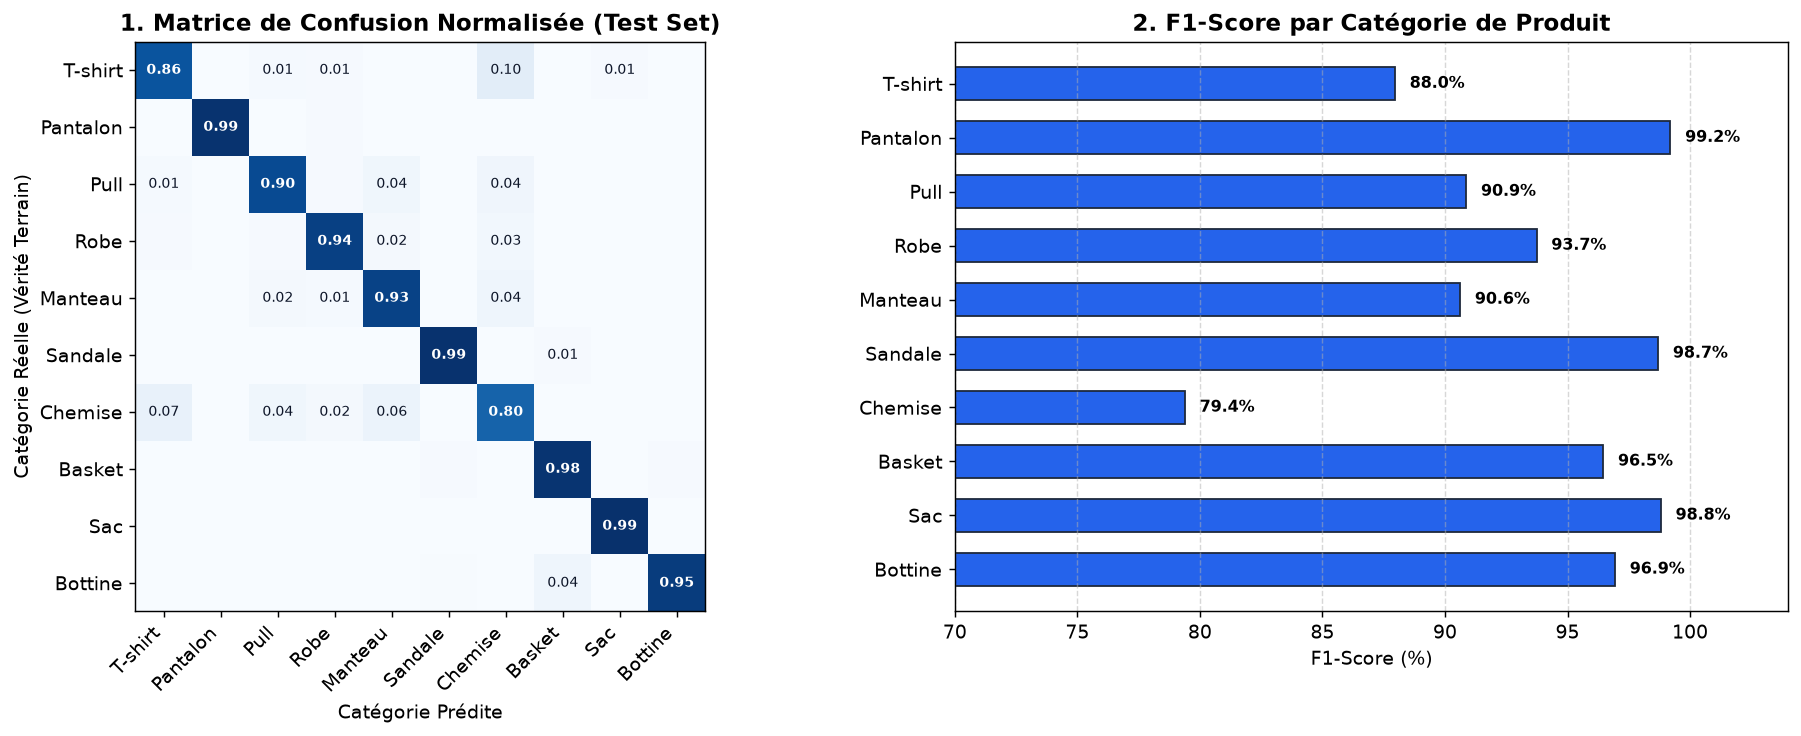

In [5]:
# ==============================================================================
# MATRICE DE CONFUSION NORMALISÉE & RAPPORT DE CLASSIFICATION PAR CATÉGORIE
# ==============================================================================
with open(BASE_DIR / 'results' / 'metrics' / 'confusion_matrix.json', 'r', encoding='utf-8') as f:
    cm_json = json.load(f)
with open(BASE_DIR / 'results' / 'metrics' / 'classification_report.json', 'r', encoding='utf-8') as f:
    report_json = json.load(f)

cm_norm = np.array(cm_json['confusion_matrix_normalized'])

# Construction du tableau récapitulatif des performances par classe
lignes_rapport = []
for cls_name in CLASS_NAMES_FR:
    if cls_name in report_json:
        r = report_json[cls_name]
        lignes_rapport.append({
            'Catégorie': cls_name,
            'Précision (%)': round(r['precision'] * 100, 2),
            'Rappel (%)': round(r['recall'] * 100, 2),
            'F1-Score (%)': round(r['f1-score'] * 100, 2),
            'Support (Images Test)': int(r['support']),
        })
df_rep = pd.DataFrame(lignes_rapport)
print('=== PERFORMANCES DÉTAILLÉES PAR CATÉGORIE SUR LES 10 000 IMAGES DE TEST ===')
print(df_rep.to_string(index=False))

# Tracé côte à côte : Matrice de confusion normalisée & F1-Score par catégorie
fig, (ax_cm, ax_f1) = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={'width_ratios': [1.2, 1]})

# 1. Heatmap de la matrice de confusion
im = ax_cm.imshow(cm_norm, cmap='Blues', vmin=0.0, vmax=1.0)
ax_cm.set_xticks(range(10))
ax_cm.set_yticks(range(10))
ax_cm.set_xticklabels(CLASS_NAMES_FR, rotation=45, ha='right')
ax_cm.set_yticklabels(CLASS_NAMES_FR)
ax_cm.set_xlabel('Catégorie Prédite')
ax_cm.set_ylabel('Catégorie Réelle (Vérité Terrain)')
ax_cm.set_title('1. Matrice de Confusion Normalisée (Test Set)', fontweight='bold')

# Annotation des valeurs numériques dans chaque cellule de la matrice
for i in range(10):
    for j in range(10):
        val = cm_norm[i, j]
        if val >= 0.01:
            ax_cm.text(j, i, f'{val:.2f}', ha='center', va='center',
                       color='white' if val > 0.5 else '#0F172A', fontsize=8, fontweight='bold' if i == j else 'normal')

# 2. Barres horizontales du F1-Score par produit
bars = ax_f1.barh(df_rep['Catégorie'][::-1], df_rep['F1-Score (%)'][::-1], color='#2563EB', edgecolor='#1E293B', height=0.6)
for bar in bars:
    w = bar.get_width()
    ax_f1.text(w + 0.6, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')
ax_f1.set_xlim(70, 104)
ax_f1.set_xlabel('F1-Score (%)')
ax_f1.set_title('2. F1-Score par Catégorie de Produit', fontweight='bold')
ax_f1.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 6. Moteur d'Inférence Vectorisé & Explicabilité Visuelle Grad-CAM

Pour expliquer **pourquoi** le CNN prédit une catégorie donnée, la méthode **Grad-CAM** (*Gradient-weighted Class Activation Mapping*) pondère les $128$ cartes d'activation $A^k$ ($7 \times 7$) de la dernière couche convolutive par leur importance $\alpha_k^c$ envers la classe prédite $c$ :
$$L_{\text{Grad-CAM}}^c = \text{ReLU}\left(\sum_{k=1}^{128} \alpha_k^c \, A^k\right)$$
Implémentons le moteur complet lisant directement les poids entraînés de `models/best_model.keras` et visualisons les cartes Grad-CAM sur 4 articles du jeu de test :

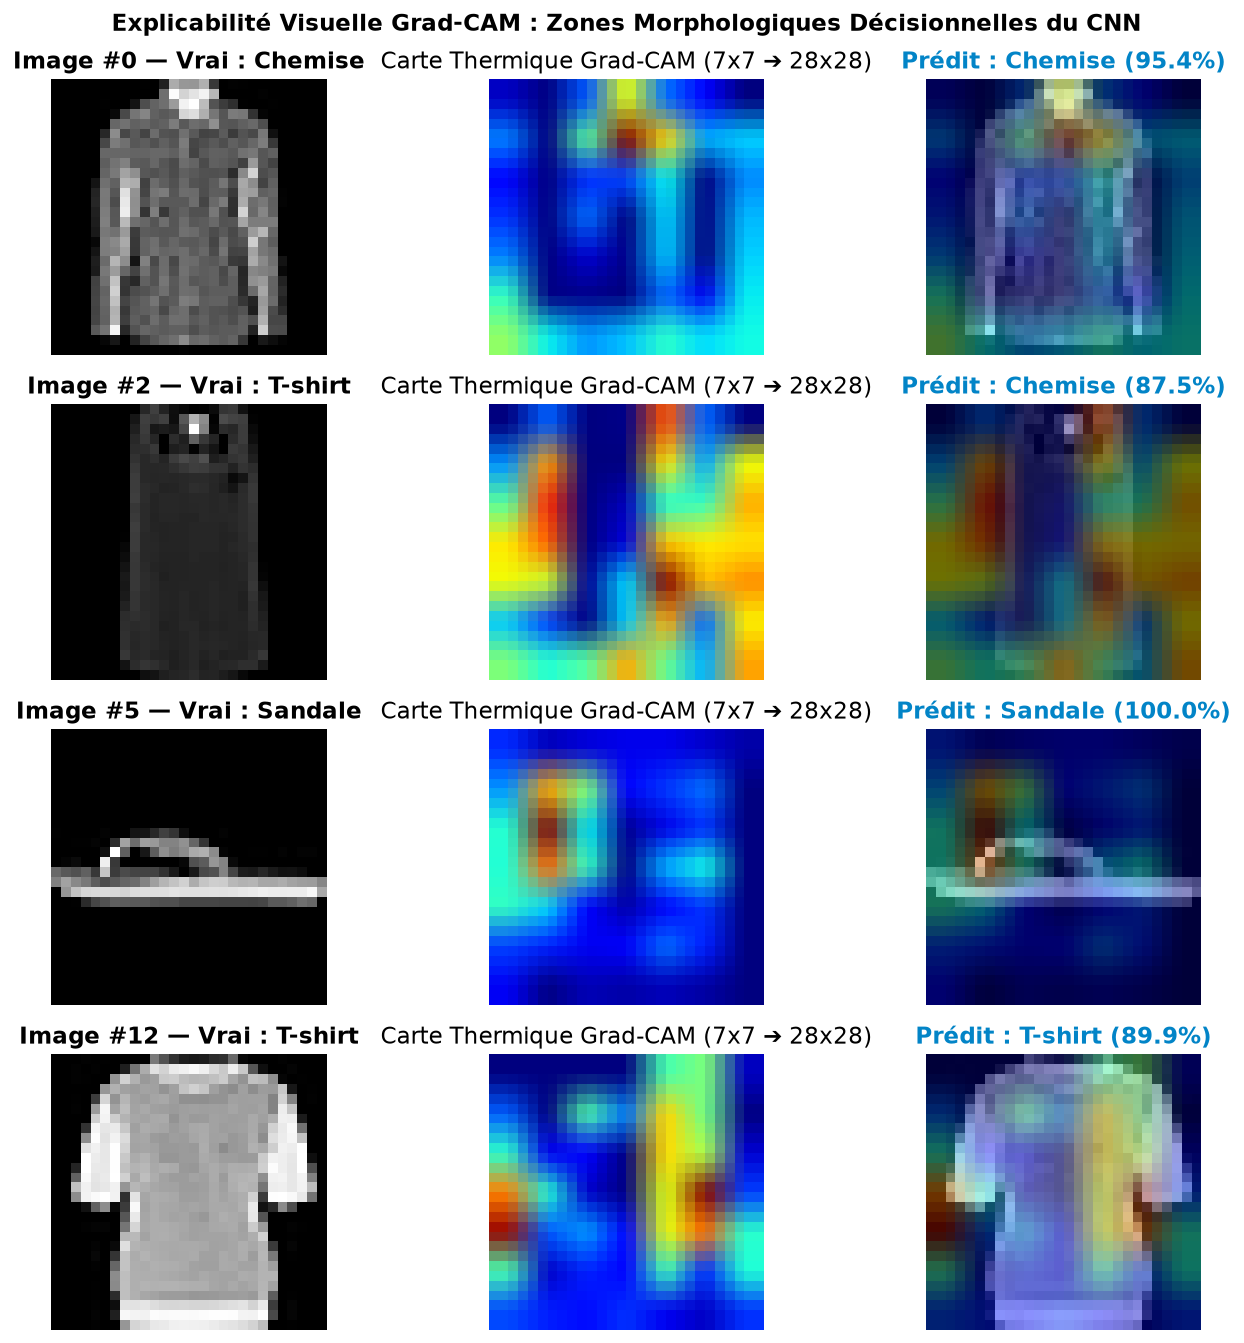

In [6]:
# ==============================================================================
# MOTEUR D'INFÉRENCE CNN VECTORISÉ & CALCUL ANALYTIQUE DE GRAD-CAM
# ==============================================================================
class NumpyCNNModel:
    # Charge directement les tenseurs de poids entraînés depuis l'archive 'models/best_model.keras'
    # et exécute la passe avant exacte du CNN Amélioré ainsi que la carte d'attention Grad-CAM.
    def __init__(self, keras_path: Path):
        self.weights: Dict[str, np.ndarray] = {}
        self.last_conv_output: Optional[np.ndarray] = None

        # Extraction du fichier HDF5 'model.weights.h5' contenu dans le fichier .keras
        with zipfile.ZipFile(keras_path, 'r') as z:
            h5_bytes = z.read('model.weights.h5')
        with h5py.File(io.BytesIO(h5_bytes), 'r') as f:
            for layer_name, grp in f['layers'].items():
                if 'vars' in grp:
                    for var_name in grp['vars'].keys():
                        self.weights[f'{layer_name}/{var_name}'] = np.array(grp['vars'][var_name], dtype=np.float32)

    # Décorateur @staticmethod :
    # Définit une fonction mathématique utilitaire rattachée à la classe qui n'utilise pas 'self'.
    @staticmethod
    def _conv_bn_relu(x: np.ndarray, w_conv: np.ndarray, b_conv: np.ndarray, bn_params: List[np.ndarray]) -> np.ndarray:
        # 1. Convolution 2D (3x3, padding 'same' par bordure de 1 zéro)
        _, h, w, _ = x.shape
        cout = w_conv.shape[-1]
        pad_x = np.pad(x, ((0, 0), (1, 1), (1, 1), (0, 0)), mode='constant')
        out = np.zeros((1, h, w, cout), dtype=np.float32)
        for i in range(h):
            for j in range(w):
                out[0, i, j, :] = np.tensordot(pad_x[0, i:i+3, j:j+3, :], w_conv, axes=([0, 1, 2], [0, 1, 2]))
        out += b_conv
        # 2. Batch Normalization : ((x - mean) / sqrt(var + eps)) * gamma + beta
        gamma, beta, mean, var = bn_params
        out = ((out - mean) / np.sqrt(var + 1e-3)) * gamma + beta
        # 3. Activation non-linéaire ReLU : max(0, x)
        return np.maximum(out, 0.0)

    # Décorateur @staticmethod : sous-échantillonnage spatial MaxPooling 2x2 sans dépendance à 'self'.
    @staticmethod
    def _max_pool2d(x: np.ndarray) -> np.ndarray:
        _, h, w, c = x.shape
        return x.reshape(1, h // 2, 2, w // 2, 2, c).max(axis=(2, 4))

    def _bn_weights(self, prefix: str) -> List[np.ndarray]:
        return [self.weights[f'{prefix}/{k}'] for k in range(4)]

    def predict(self, x: np.ndarray) -> np.ndarray:
        # Bloc 1 : 2 convolutions (32 filtres) + MaxPool -> (1, 14, 14, 32)
        x = self._conv_bn_relu(x, self.weights['conv2d/0'], self.weights['conv2d/1'], self._bn_weights('batch_normalization'))
        x = self._conv_bn_relu(x, self.weights['conv2d_1/0'], self.weights['conv2d_1/1'], self._bn_weights('batch_normalization_1'))
        x = self._max_pool2d(x)
        # Bloc 2 : 2 convolutions (64 filtres) + MaxPool -> (1, 7, 7, 64)
        x = self._conv_bn_relu(x, self.weights['conv2d_2/0'], self.weights['conv2d_2/1'], self._bn_weights('batch_normalization_2'))
        x = self._conv_bn_relu(x, self.weights['conv2d_3/0'], self.weights['conv2d_3/1'], self._bn_weights('batch_normalization_3'))
        x = self._max_pool2d(x)
        # Bloc 3 : Dernière convolution (128 filtres, 7x7) conservée en mémoire pour Grad-CAM
        self.last_conv_output = self._conv_bn_relu(x, self.weights['conv2d_4/0'], self.weights['conv2d_4/1'], self._bn_weights('batch_normalization_4'))

        # Global Average Pooling 2D (moyenne spatiale 7x7 -> vecteur de 128 caractéristiques)
        gap = np.mean(self.last_conv_output, axis=(1, 2))
        d1 = np.dot(gap, self.weights['dense/0']) + self.weights['dense/1']
        gamma, beta, mean, var = self._bn_weights('batch_normalization_5')
        d1_act = np.maximum(((d1 - mean) / np.sqrt(var + 1e-3)) * gamma + beta, 0.0)

        # Couche de sortie Softmax (10 probabilités sommant à 1.0)
        logits = np.dot(d1_act, self.weights['dense_1/0']) + self.weights['dense_1/1']
        exp_l = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
        return exp_l / np.sum(exp_l, axis=-1, keepdims=True)

    def compute_gradcam(self, class_id: int) -> np.ndarray:
        # Calcule la carte d'attention Grad-CAM (7x7) en pondérant les 128 cartes d'activation
        # par leur contribution effective vers la classe prédite 'class_id'.
        gamma = self.weights['batch_normalization_5/0']
        var = self.weights['batch_normalization_5/3']
        scale = gamma / np.sqrt(var + 1e-3)
        effective_w = np.dot(self.weights['dense/0'] * scale, self.weights['dense_1/0'][:, class_id])
        fmaps = self.last_conv_output[0]
        heatmap = np.maximum(np.tensordot(fmaps, effective_w, axes=([2], [0])), 0.0)
        max_v = float(np.max(heatmap))
        return (heatmap / max_v) if max_v > 0 else np.mean(fmaps, axis=-1)

# Instanciation du modèle entraîné et démonstration Grad-CAM sur 4 produits différents
cnn_model = NumpyCNNModel(BASE_DIR / 'models' / 'best_model.keras')
demo_indices = [0, 2, 5, 12]

fig, axes = plt.subplots(4, 3, figsize=(11, 10.5))
for row_i, idx in enumerate(demo_indices):
    tensor, disp_28 = preprocess_image(x_samples[idx])
    probs = np.squeeze(cnn_model.predict(tensor))
    pred_id = int(np.argmax(probs))
    true_id = int(y_samples[idx])

    # Calcul et superposition de la carte thermique Grad-CAM
    heat_7x7 = cnn_model.compute_gradcam(pred_id)
    colored = (mpl.colormaps['jet'](np.clip(heat_7x7, 0.0, 1.0))[:, :, :3] * 255).astype(np.uint8)
    heat_28 = np.array(Image.fromarray(colored).resize((28, 28), Image.Resampling.BILINEAR))
    overlay = np.array(Image.blend(Image.fromarray(disp_28).convert('RGB'), Image.fromarray(heat_28), alpha=0.45))

    axes[row_i, 0].imshow(disp_28, cmap='gray')
    axes[row_i, 0].set_title(f'Image #{idx} — Vrai : {CLASS_NAMES_FR[true_id]}', fontweight='bold')
    axes[row_i, 0].axis('off')

    axes[row_i, 1].imshow(heat_28)
    axes[row_i, 1].set_title('Carte Thermique Grad-CAM (7x7 ➔ 28x28)')
    axes[row_i, 1].axis('off')

    axes[row_i, 2].imshow(overlay)
    axes[row_i, 2].set_title(f'Prédit : {CLASS_NAMES_FR[pred_id]} ({probs[pred_id]*100:.1f}%)', color='#0284C7', fontweight='bold')
    axes[row_i, 2].axis('off')

plt.suptitle('Explicabilité Visuelle Grad-CAM : Zones Morphologiques Décisionnelles du CNN', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 7. Laboratoire Interactif de Test en Direct

Modifiez la constante `INDEX_IMAGE_TEST` (entre `0` et `499`) dans la cellule ci-dessous pour inspecter instantanément la prédiction du CNN, le classement Top-5 Softmax et l'explication Grad-CAM sur n'importe quel produit du jeu de test :

In [7]:
# ==============================================================================
# 🎛️ LABORATOIRE INTERACTIF : TESTEZ N'IMPORTE QUELLE IMAGE DU JEU DE TEST (0 à 499)
# ==============================================================================
INDEX_IMAGE_TEST = 15       # Choisissez un numéro d'image entre 0 et 499
ALPHA_SUPERPOSITION = 0.45  # Intensité de la carte thermique Grad-CAM (entre 0.1 et 0.9)

# 1. Prétraitement et inférence CNN
tensor_test, disp_test = preprocess_image(x_samples[INDEX_IMAGE_TEST])
probs_test = np.squeeze(cnn_model.predict(tensor_test))
pred_cls = int(np.argmax(probs_test))
true_cls = int(y_samples[INDEX_IMAGE_TEST])

# 2. Extraction du Top 5 des catégories les plus probables
top5_idx = np.argsort(probs_test)[::-1][:5]
df_top5 = pd.DataFrame([
    {
        'Rang': r,
        'Catégorie (FR)': CLASS_NAMES_FR[i],
        'Catégorie (EN)': CLASS_NAMES_EN[i],
        'Probabilité Softmax (%)': f'{probs_test[i]*100:.2f} %'
    }
    for r, i in enumerate(top5_idx, start=1)
])

statut = '✅ PRÉDICTION EXACTE' if pred_cls == true_cls else '⚠️ CONFUSION MORPHOLOGIQUE'
print(f'=== RÉSULTAT D\'ANALYSE SUR L\'IMAGE #{INDEX_IMAGE_TEST} ({statut}) ===')
print(f'• Vérité terrain    : {CLASS_NAMES_FR[true_cls]} ({CLASS_NAMES_EN[true_cls]})')
print(f'• Prédiction du CNN : {CLASS_NAMES_FR[pred_cls]} (Confiance = {probs_test[pred_cls]*100:.2f} %)\n')
print(df_top5.to_string(index=False))

=== RÉSULTAT D'ANALYSE SUR L'IMAGE #15 (✅ PRÉDICTION EXACTE) ===
• Vérité terrain    : Chemise (Shirt)
• Prédiction du CNN : Chemise (Confiance = 99.99 %)

 Rang Catégorie (FR) Catégorie (EN) Probabilité Softmax (%)
    1        Chemise          Shirt                 99.99 %
    2        Manteau           Coat                  0.01 %
    3        T-shirt    T-shirt/top                  0.00 %
    4           Pull       Pullover                  0.00 %
    5           Robe          Dress                  0.00 %
